In [1]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [2]:
import sklearn.preprocessing as preproc
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score

In [3]:
import yfinance as yf

# Define the ticker symbol for S&P 500 (^GSPC)
# For example, https://finance.yahoo.com/quote/%5EGSPC/history/?period1=1569174385&period2=1727027123
ticker_symbol = "AAPL"

# Download historical data (adjust the period as needed, e.g., '1mo', '1y', 'max')
data = yf.download(
    ticker_symbol,
    start="2016-10-08",
    end="2026-10-09",
    interval="1d",
    auto_adjust=False,
    multi_level_index=False,
    progress=False
)


data = data.reset_index()

data.columns.name = None

data.to_csv('AAPL_historical_data.csv')

print("Data downloaded and saved as AAPL_historical_data.csv")

Data downloaded and saved as AAPL_historical_data.csv


In [4]:
data.to_csv(
    "AAPL_historical_data.csv",
    index=False
)

print("Dataset saved successfully.")
print("Dataset shape:", data.shape)
print("Columns:", data.columns.tolist())

Dataset saved successfully.
Dataset shape: (2513, 7)
Columns: ['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


In [5]:
data.head()

,Date,Adj Close,Close,High,Low,Open,Volume
0,2016-10-10,26.538963,29.012501,29.187500,28.680000,28.754999,144944000
1,2016-10-11,26.596140,29.075001,29.672501,29.049999,29.424999,256164000
2,2016-10-12,26.833969,29.334999,29.495001,29.187500,29.337500,150347200
3,2016-10-13,26.751642,29.245001,29.360001,28.930000,29.197500,140769600
4,2016-10-14,26.900290,29.407499,29.542500,29.282499,29.469999,142608800


In [6]:
# Preserve an unchanged copy of the downloaded dataset
data_original = data.copy()

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2513 entries, 0 to 2512
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       2513 non-null   datetime64[ns]
 1   Adj Close  2513 non-null   float64       
 2   Close      2513 non-null   float64       
 3   High       2513 non-null   float64       
 4   Low        2513 non-null   float64       
 5   Open       2513 non-null   float64       
 6   Volume     2513 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 137.6 KB


In [8]:
data.describe()

,Date,Adj Close,Close,High,Low,Open,Volume
count,2513,2513.000000,2513.000000,2513.000000,2513.000000,2513.000000,2.513000e+03
mean,2021-10-07 13:46:17.715877376,134.567372,136.958811,138.329123,135.448595,136.820037,9.316546e+07
min,2016-10-10 00:00:00,24.298473,26.427500,26.920000,26.020000,26.642500,1.791060e+07
25%,2019-04-10 00:00:00,48.759983,51.117500,51.527500,50.672501,51.070000,5.451150e+07
50%,2021-10-06 00:00:00,138.752625,142.059998,143.520004,139.899994,142.059998,8.107720e+07
75%,2024-04-08 00:00:00,189.252686,191.559998,192.979996,189.910004,191.440002,1.136056e+08
max,2026-10-08 00:00:00,341.070007,341.070007,345.339996,338.750000,341.079987,4.479400e+08
std,NaN,82.203313,81.659155,82.451299,80.773683,81.555785,5.361629e+07


In [9]:
data.isnull().sum()

Date         0
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

In [10]:
data.duplicated().sum()

np.int64(0)

In [11]:
duplicate_dates = data["Date"].duplicated().sum()

print("Number of duplicated dates:", duplicate_dates)

Number of duplicated dates: 0


This graph shows how Apple’s adjusted share price changed over time. Adj Close was selected because it accounts for changes such as dividends and stock splits.

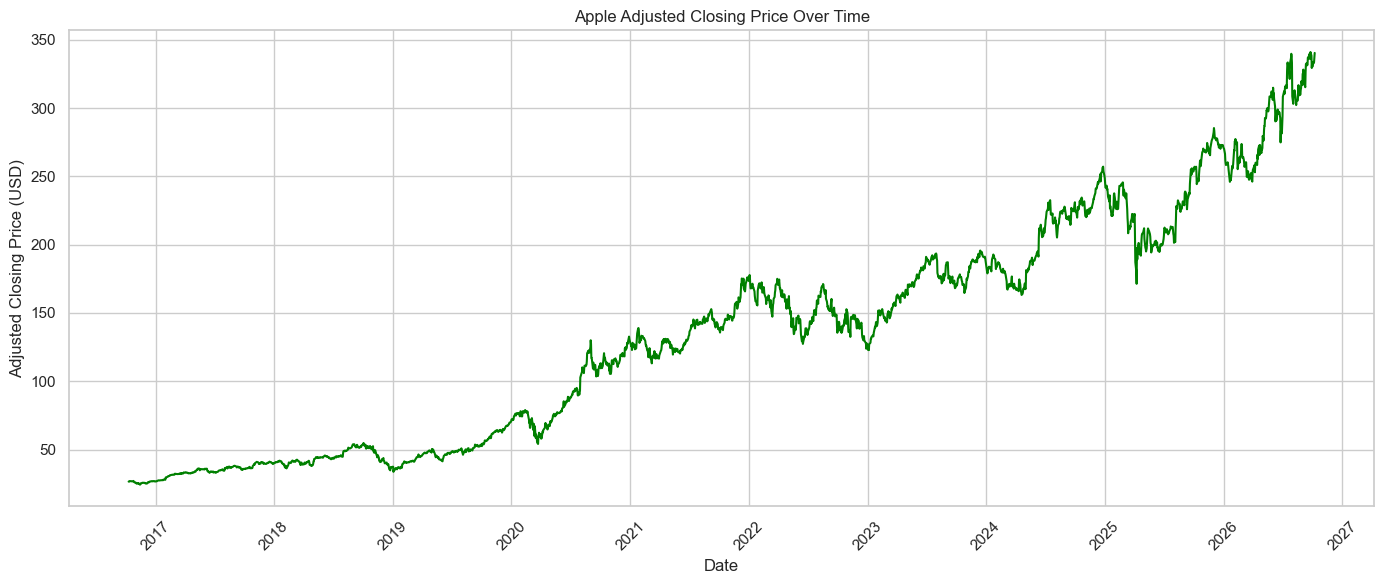

In [12]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(14, 6))

plt.plot(
    data["Date"],
    data["Adj Close"],
    color="green",
    linewidth=1.5
)

plt.title("Apple Adjusted Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The graph shows a strong upward trend in Apple’s adjusted closing price during the ten-year period. The price increased from approximately 25 dolares  to  more  than 340 dolares, although several temporary declines and periods of greater price variation can also be observed. This trend suggests that the original price series may not be stationary, but this will be confirmed later using the Augmented Dickey-Fuller test

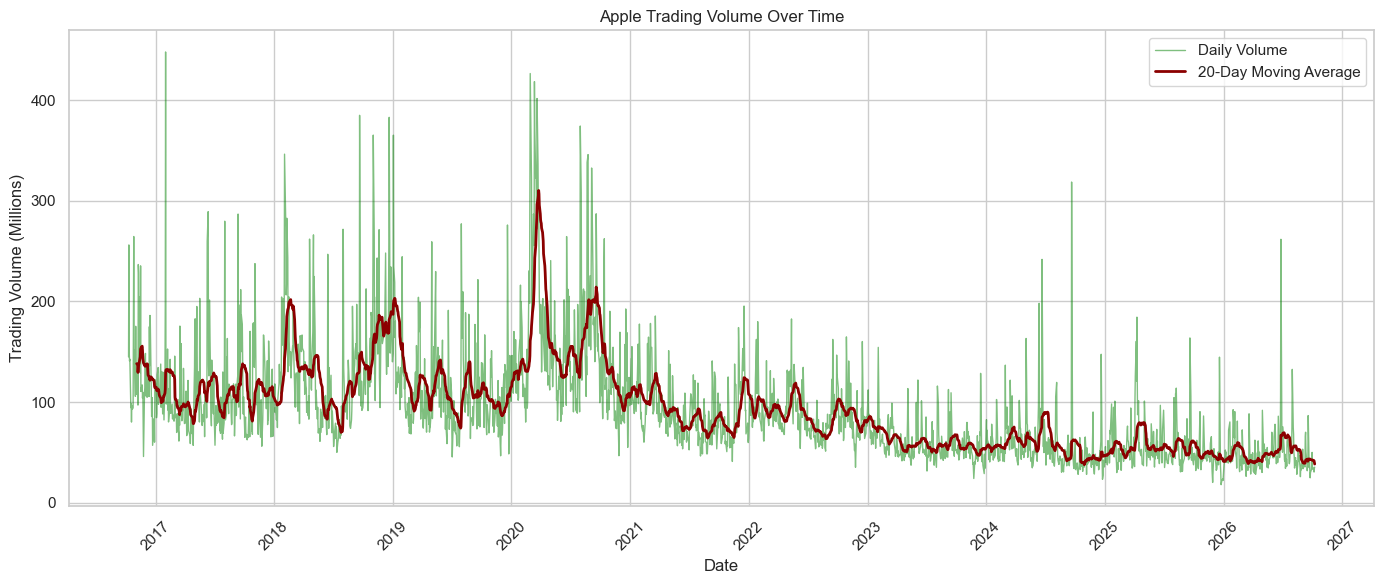

In [13]:
# Convert Volume to millions for easier interpretation
volume_millions = data["Volume"] / 1_000_000

# Calculate the 20-day moving average
volume_ma20 = volume_millions.rolling(window=20).mean()

plt.figure(figsize=(14, 6))

plt.plot(
    data["Date"],
    volume_millions,
    color="green",
    alpha=0.5,
    linewidth=1,
    label="Daily Volume"
)

plt.plot(
    data["Date"],
    volume_ma20,
    color="darkred",
    linewidth=2,
    label="20-Day Moving Average"
)

plt.title("Apple Trading Volume Over Time")
plt.xlabel("Date")
plt.ylabel("Trading Volume (Millions)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The graph shows considerable variation in Apple’s daily trading volume. The highest volumes were mainly observed between 2017 and 2020, followed by a general decline in the 20-day moving average. Some isolated peaks can still be observed in the most recent years, indicating days of unusually high market activity.

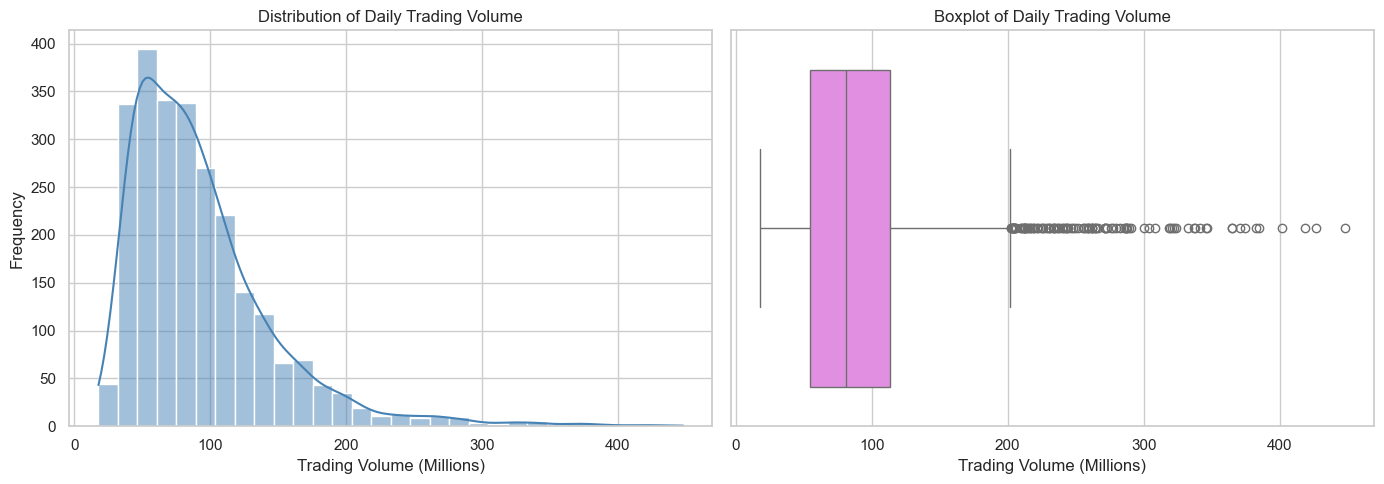

In [14]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Histogram
sns.histplot(
    volume_millions,
    bins=30,
    kde=True,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Distribution of Daily Trading Volume")
axes[0].set_xlabel("Trading Volume (Millions)")
axes[0].set_ylabel("Frequency")

# Boxplot
sns.boxplot(
    x=volume_millions,
    color="violet",
    ax=axes[1]
)

axes[1].set_title("Boxplot of Daily Trading Volume")
axes[1].set_xlabel("Trading Volume (Millions)")

plt.tight_layout()
plt.show()

The trading volume has a positively skewed distribution, with most observations concentrated at lower and moderate values. The boxplot identified several unusually high volumes above approximately 200 million shares. These observations were retained because they may represent genuine periods of increased market activity rather than data errors

<Axes: >

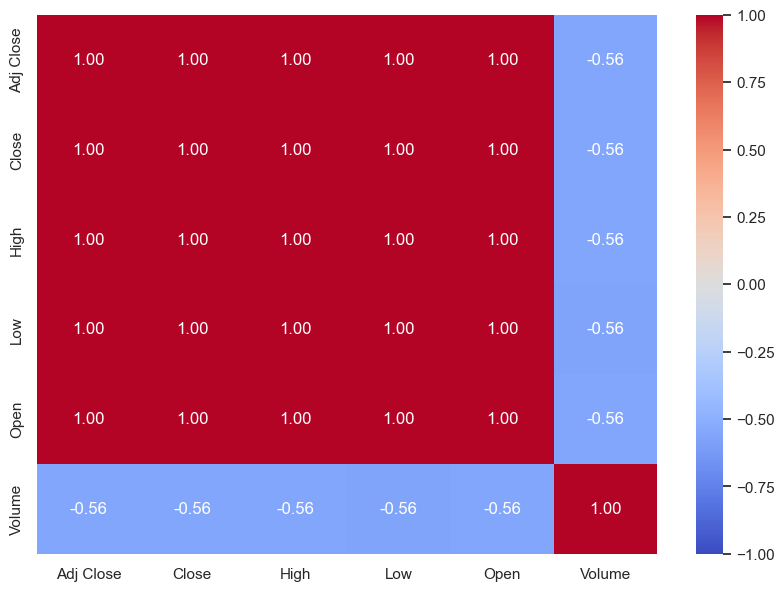

In [15]:
#Correlations 

numerical_columns = [
    "Adj Close",
    "Close",
    "High",
    "Low",
    "Open",
    "Volume"
]

correlation_matrix = data[numerical_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

The correlation matrix analysis shows a very strong positive correlation between the adjusted closing, opening, high, and low prices. This is expected, as these variables indicate different price measures of the same stock and generally move together. Volume shows a moderate negative correlation of approximately -0.56 with the price variables. However, correlation does not necessarily indicate causation.

Experimentation with new variables created to represent the daily behavior of Apple's stock. These variables measure daily return, intraday price range, price change between open and close, volume change, and 20-day cumulative volatility. They provide more relevant information for cluster analysis than using only the original price variables.

In [16]:

data_features = data.copy()


data_features["Daily_Return"] = data_features["Adj Close"].pct_change() * 100


data_features["Intraday_Range"] = (
    (data_features["High"] - data_features["Low"])
    / data_features["Open"]
) * 100


data_features["Open_Close_Change"] = (
    (data_features["Close"] - data_features["Open"])
    / data_features["Open"]
) * 100

data_features["Volume_Change"] = data_features["Volume"].pct_change() * 100


data_features["Rolling_Volatility"] = (
    data_features["Daily_Return"].rolling(window=20).std()
)

data_features.head(25)

,Date,Adj Close,Close,High,Low,Open,Volume,Daily_Return,Intraday_Range,Open_Close_Change,Volume_Change,Rolling_Volatility
0,2016-10-10,26.538963,29.012501,29.187500,28.680000,28.754999,144944000,NaN,1.764909,0.895502,NaN,NaN
1,2016-10-11,26.596140,29.075001,29.672501,29.049999,29.424999,256164000,0.215444,2.115553,-1.189460,76.733083,NaN
2,2016-10-12,26.833969,29.334999,29.495001,29.187500,29.337500,150347200,0.894225,1.048149,-0.008523,-41.308224,NaN
3,2016-10-13,26.751642,29.245001,29.360001,28.930000,29.197500,140769600,-0.306801,1.472730,0.162687,-6.370321,NaN
4,2016-10-14,26.900290,29.407499,29.542500,29.282499,29.469999,142608800,0.555657,0.882254,-0.212080,1.306532,NaN
5,2016-10-17,26.881992,29.387501,29.459999,29.195000,29.332500,94499600,-0.068019,0.903433,0.187506,-33.735085,NaN
6,2016-10-18,26.863703,29.367500,29.552500,29.362499,29.545000,98214000,-0.068036,0.643089,-0.600778,3.930599,NaN
7,2016-10-19,26.783659,29.280001,29.440001,28.450001,29.312500,80138400,-0.297963,3.377398,-0.110872,-18.404301,NaN
8,2016-10-20,26.769936,29.264999,29.344999,29.082500,29.215000,96503200,-0.051238,0.898507,0.171142,20.420672,NaN
9,2016-10-21,26.664743,29.150000,29.227501,29.070000,29.202499,92770800,-0.392949,0.539342,-0.179778,-3.867644,NaN


In [17]:
print("Number of rows:", data_features.shape[0])
print("Number of columns:", data_features.shape[1])
print("\nColumn names:")
print(data_features.columns.tolist())

print("\nMissing values:")
print(data_features.isnull().sum())

Number of rows: 2513
Number of columns: 12

Column names:
['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'Intraday_Range', 'Open_Close_Change', 'Volume_Change', 'Rolling_Volatility']

Missing values:
Date                   0
Adj Close              0
Close                  0
High                   0
Low                    0
Open                   0
Volume                 0
Daily_Return           1
Intraday_Range         0
Open_Close_Change      0
Volume_Change          1
Rolling_Volatility    20
dtype: int64


In [18]:
missing_rows = data_features[
    data_features[
        [
            "Daily_Return",
            "Volume_Change",
            "Rolling_Volatility"
        ]
    ].isnull().any(axis=1)
]

print("Number of rows with missing values:", len(missing_rows))

missing_rows[
    [
        "Date",
        "Adj Close",
        "Volume",
        "Daily_Return",
        "Volume_Change",
        "Rolling_Volatility"
    ]
    ]

Number of rows with missing values: 20


,Date,Adj Close,Volume,Daily_Return,Volume_Change,Rolling_Volatility
0,2016-10-10,26.538963,144944000,NaN,NaN,NaN
1,2016-10-11,26.596140,256164000,0.215444,76.733083,NaN
2,2016-10-12,26.833969,150347200,0.894225,-41.308224,NaN
3,2016-10-13,26.751642,140769600,-0.306801,-6.370321,NaN
4,2016-10-14,26.900290,142608800,0.555657,1.306532,NaN
5,2016-10-17,26.881992,94499600,-0.068019,-33.735085,NaN
6,2016-10-18,26.863703,98214000,-0.068036,3.930599,NaN
7,2016-10-19,26.783659,80138400,-0.297963,-18.404301,NaN
8,2016-10-20,26.769936,96503200,-0.051238,20.420672,NaN
9,2016-10-21,26.664743,92770800,-0.392949,-3.867644,NaN


In [19]:
missing_rows[
    [
        "Daily_Return",
        "Volume_Change",
        "Rolling_Volatility"
    ]
].isnull()


,Daily_Return,Volume_Change,Rolling_Volatility
0,True,True,True
1,False,False,True
2,False,False,True
3,False,False,True
4,False,False,True
5,False,False,True
6,False,False,True
7,False,False,True
8,False,False,True
9,False,False,True


In [20]:
missing_rows[
    [
        "Adj Close",
        "Volume",
        "Daily_Return",
        "Intraday_Range",
        "Open_Close_Change",
        "Volume_Change"
    ]
].describe()

,Adj Close,Volume,Daily_Return,Intraday_Range,Open_Close_Change,Volume_Change
count,20.000000,2.000000e+01,19.000000,20.000000,20.000000,19.000000
mean,26.369771,1.381624e+08,-0.306853,1.439467,-0.118717,5.986895
std,0.619863,5.132222e+07,0.832119,0.762450,0.683002,41.031035
min,25.017935,8.013840e+07,-2.249476,0.539342,-1.736296,-47.739596
25%,25.995839,9.778630e+07,-0.782638,0.896433,-0.309254,-24.312803
50%,26.630442,1.307980e+08,-0.158258,1.260440,-0.052656,1.306532
75%,26.841403,1.506221e+08,0.152570,1.816633,0.204217,17.458801
max,27.042078,2.645368e+08,0.900536,3.377398,1.119761,104.467536


In [21]:
feature_columns = [
    "Daily_Return",
    "Intraday_Range",
    "Open_Close_Change",
    "Volume_Change",
    "Rolling_Volatility"
]


data_features[feature_columns] = (
    data_features[feature_columns]
    .replace([np.inf, -np.inf], np.nan)
)


clustering_data = (
    data_features
    .dropna(subset=feature_columns)
    .copy()
)


clustering_data.reset_index(drop=True, inplace=True)

print("Rows before cleaning:", len(data_features))
print("Rows after cleaning:", len(clustering_data))
print("Columns after cleaning:", clustering_data.shape[1])

print("\nMissing values in clustering features:")
print(clustering_data[feature_columns].isnull().sum())

print("\nInfinite values:")
print(np.isinf(clustering_data[feature_columns]).sum())

Rows before cleaning: 2513
Rows after cleaning: 2493
Columns after cleaning: 12

Missing values in clustering features:
Daily_Return          0
Intraday_Range        0
Open_Close_Change     0
Volume_Change         0
Rolling_Volatility    0
dtype: int64

Infinite values:
Daily_Return          0
Intraday_Range        0
Open_Close_Change     0
Volume_Change         0
Rolling_Volatility    0
dtype: int64


Analyzing only 20 lines, which represents approximately 0.80% of the dataset, these were removed because they did not contain sufficient historical observations for the calculation of the 20-day moving average volatility. The original dataset is preserved, while a separate, clean copy containing 2,493 lines was created for grouping.

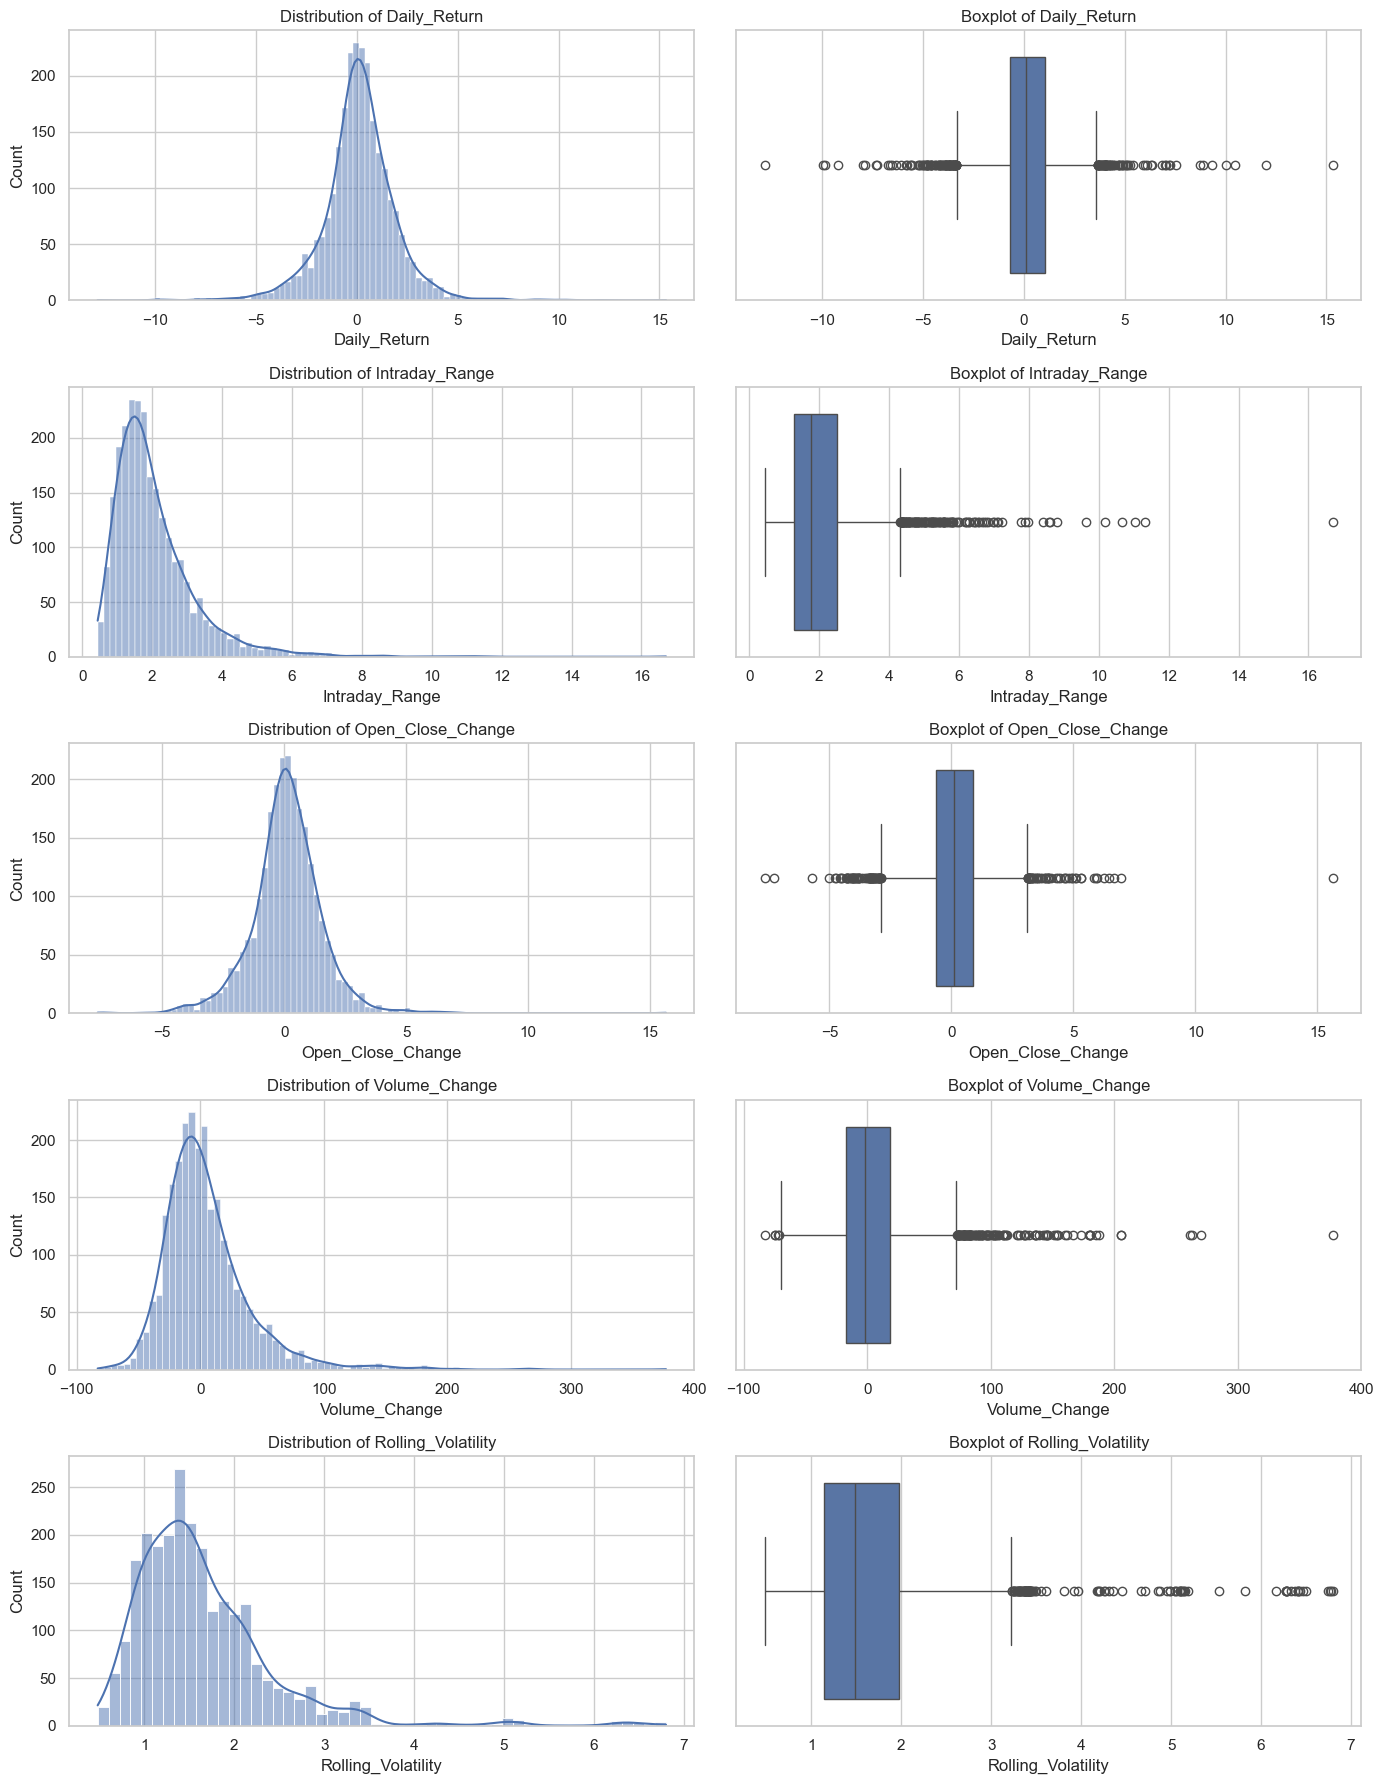

In [22]:
fig, axes = plt.subplots(
    nrows=len(feature_columns),
    ncols=2,
    figsize=(14, 18)
)

for i, column in enumerate(feature_columns):

    sns.histplot(
        clustering_data[column],
        kde=True,
        ax=axes[i, 0]
    )
    axes[i, 0].set_title(f"Distribution of {column}")

    sns.boxplot(
        x=clustering_data[column],
        ax=axes[i, 1]
    )
    axes[i, 1].set_title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

The distributions and boplots reveale several extreme observations. Daily return and opening-to-closing change were centred near zero but contained outliers on both sides. Intraday range, volume change and rolling volatility were positively skewed and contained high-value outliers. These observations were retained because they may represent genuine periods of unusual market activity<RobustScaler was selected because it is less sensitive to extreme values than StandardScaler

In [23]:
distribution_summary = clustering_data[feature_columns].agg(
    ["mean", "median", "std", "min", "max", "skew"]
).T

distribution_summary

,mean,median,std,min,max,skew
Daily_Return,0.121682,0.117671,1.840450,-12.864706,15.328850,0.118179
Intraday_Range,2.061132,1.765954,1.214877,0.439312,16.702531,2.753386
Open_Close_Change,0.108823,0.102470,1.435701,-7.648634,15.644088,0.464071
Volume_Change,5.036001,-1.707699,36.139792,-83.009283,377.199306,2.224211
Rolling_Volatility,1.659051,1.486464,0.812307,0.481538,6.800421,2.479359


In [24]:
import pandas as pd
from sklearn.preprocessing import RobustScaler

X = clustering_data[feature_columns].copy()


robust_scaler = RobustScaler()
X_scaled = robust_scaler.fit_transform(X)


scaled_features = pd.DataFrame(
    X_scaled,
    columns=feature_columns,
    index=clustering_data.index
)

print("Scaled dataset shape:", scaled_features.shape)
scaled_features.describe().T

Scaled dataset shape: (2493, 5)


,count,mean,std,min,25%,50%,75%,max
Daily_Return,2493.0,0.002307,1.058286,-7.465054,-0.481020,0.0,0.518980,8.746648
Intraday_Range,2493.0,0.244255,1.005294,-1.097778,-0.395816,0.0,0.604184,12.359809
Open_Close_Change,2493.0,0.004244,0.959250,-5.178825,-0.481595,0.0,0.518405,10.383982
Volume_Change,2493.0,0.188586,1.010640,-2.273577,-0.434149,0.0,0.565851,10.596032
Rolling_Volatility,2493.0,0.206704,0.972881,-1.203576,-0.417915,0.0,0.582085,6.364404


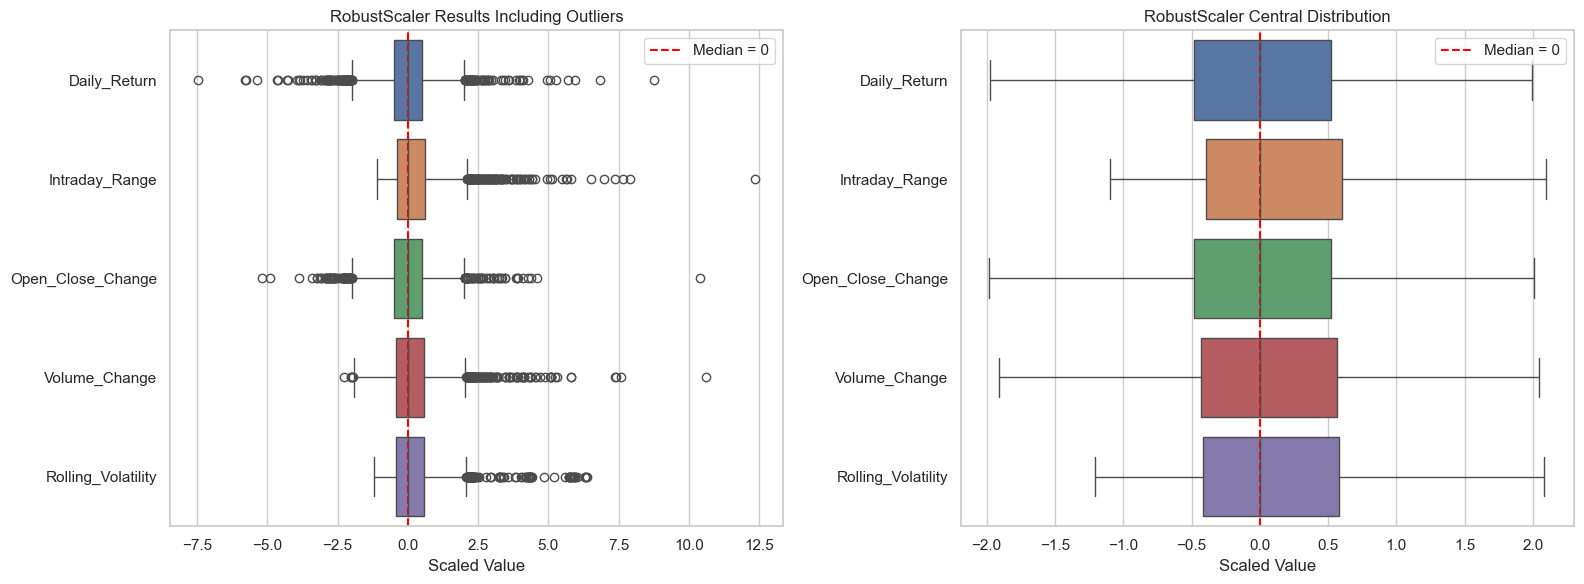

In [25]:
ig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(
    data=scaled_features,
    orient="h",
    ax=axes[0],
    showfliers=True
)

axes[0].axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Median = 0"
)

axes[0].set_title("RobustScaler Results Including Outliers")
axes[0].set_xlabel("Scaled Value")
axes[0].legend()


sns.boxplot(
    data=scaled_features,
    orient="h",
    ax=axes[1],
    showfliers=False
)

axes[1].axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Median = 0"
)

axes[1].set_title("RobustScaler Central Distribution")
axes[1].set_xlabel("Scaled Value")
axes[1].legend()

plt.tight_layout()
plt.show()

The box plots reflect the five characteristics after applying the RobustScaler. Their medians were centered at zero, and their interquartile ranges became comparable. The first graph shows all extreme observations, while the second hides them for greater visual clarity.Outliers were retained in the dataset because they may represent genuine periods of unusual market activity

PCA

In [26]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(scaled_features)


pca_variance = pd.DataFrame({
    "Principal_Component": [
        f"PC{i}" for i in range(1, len(feature_columns) + 1)
    ],
    "Explained_Variance": pca_full.explained_variance_ratio_,
    "Cumulative_Variance": pca_full.explained_variance_ratio_.cumsum()
})

pca_variance

,Principal_Component,Explained_Variance,Cumulative_Variance
0,PC1,0.361488,0.361488
1,PC2,0.304761,0.666248
2,PC3,0.204685,0.870933
3,PC4,0.083683,0.954616
4,PC5,0.045384,1.000000


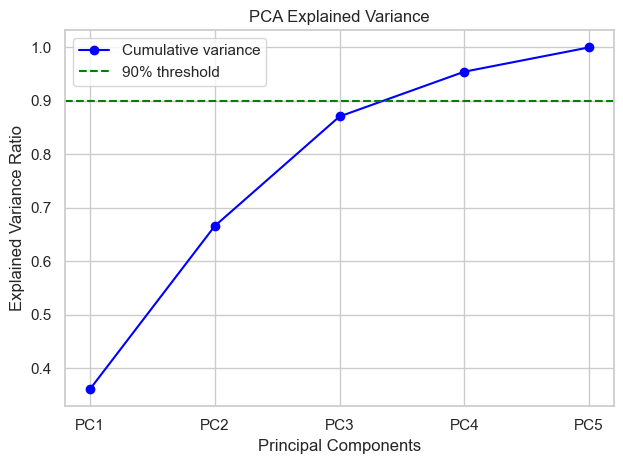

In [27]:
plt.plot(
    pca_variance["Principal_Component"],
    pca_variance["Cumulative_Variance"],
    marker="o",
    color="blue",
    label="Cumulative variance"
)

plt.axhline(
    y=0.90,
    color="green",
    linestyle="--",
    label="90% threshold"
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
pca = PCA(n_components=4)

X_pca = pca.fit_transform(scaled_features)

pca_data = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2", "PC3", "PC4"],
    index=clustering_data.index
)

print("Dataset before PCA:", scaled_features.shape)
print("Dataset after PCA:", pca_data.shape)
print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

Dataset before PCA: (2493, 5)
Dataset after PCA: (2493, 4)
Total explained variance: 0.9546155407020771


PCA reduced the five scaled characteristics to four components, retaining 95.46% of the total variance. The final dataset contained 2,493 observations and four uncorrelated components for clustering

In [29]:
print(type(X_scaled))
print(type(X_pca))
print(type(pca_data))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'pandas.core.frame.DataFrame'>


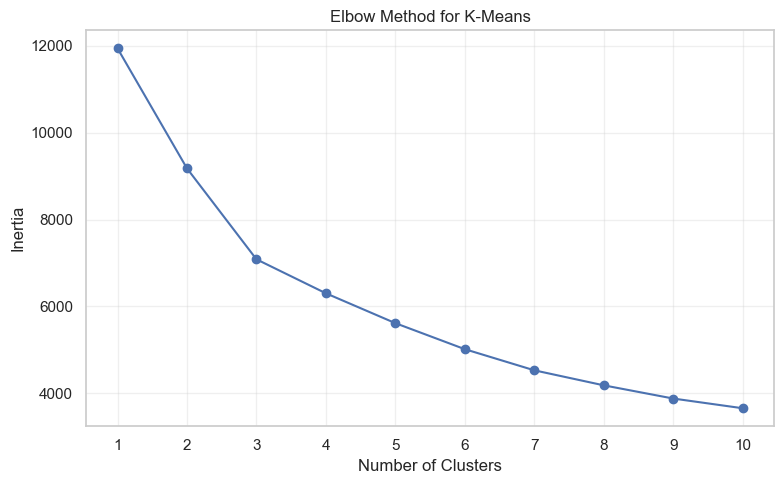

In [30]:

inertia_values = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(pca_data)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The Elbow Method was used to identify a suitable number of clusters by comparing the K-Means inertia for values of k from 1 to 10.

In [31]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

silhouette_results = []

for k in range(2, 7):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(pca_data)

    score = silhouette_score(
        pca_data,
        labels
    )

    silhouette_results.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": score
    })

silhouette_table = pd.DataFrame(silhouette_results)
silhouette_table

,Number_of_Clusters,Silhouette_Score
0,2,0.380818
1,3,0.363085
2,4,0.336586
3,5,0.283077
4,6,0.264553


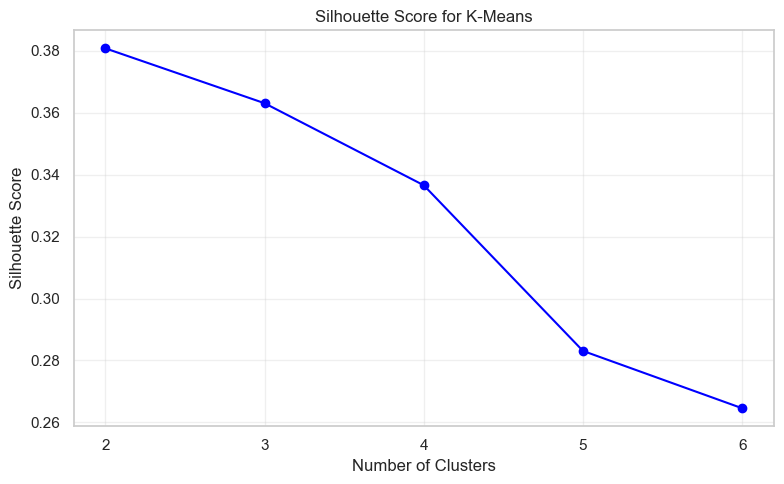

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    silhouette_table["Number_of_Clusters"],
    silhouette_table["Silhouette_Score"],
    marker="o",
    color="blue"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for K-Means")
plt.xticks(range(2, 7))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Analysis of the Elbow Method suggests that three groupings may be appropriate, as the reduction in inertia becomes more gradual after k = 3. The Silhouette Index was subsequently calculated to confirm this selection

In [33]:

evaluation_results = []

for k in range(2, 7):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(pca_data)

    evaluation_results.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": silhouette_score(
            pca_data,
            labels
        ),
        "Davies_Bouldin_Index": davies_bouldin_score(
            pca_data,
            labels
        )
    })

cluster_evaluation = pd.DataFrame(evaluation_results)
cluster_evaluation

,Number_of_Clusters,Silhouette_Score,Davies_Bouldin_Index
0,2,0.380818,1.305407
1,3,0.363085,1.172233
2,4,0.336586,1.142387
3,5,0.283077,1.202352
4,6,0.264553,1.151742


three clusters showed a balanced result in both metrics and agreed with the Elbow Method. Therefore, three clusters were selected for the final K-Means model

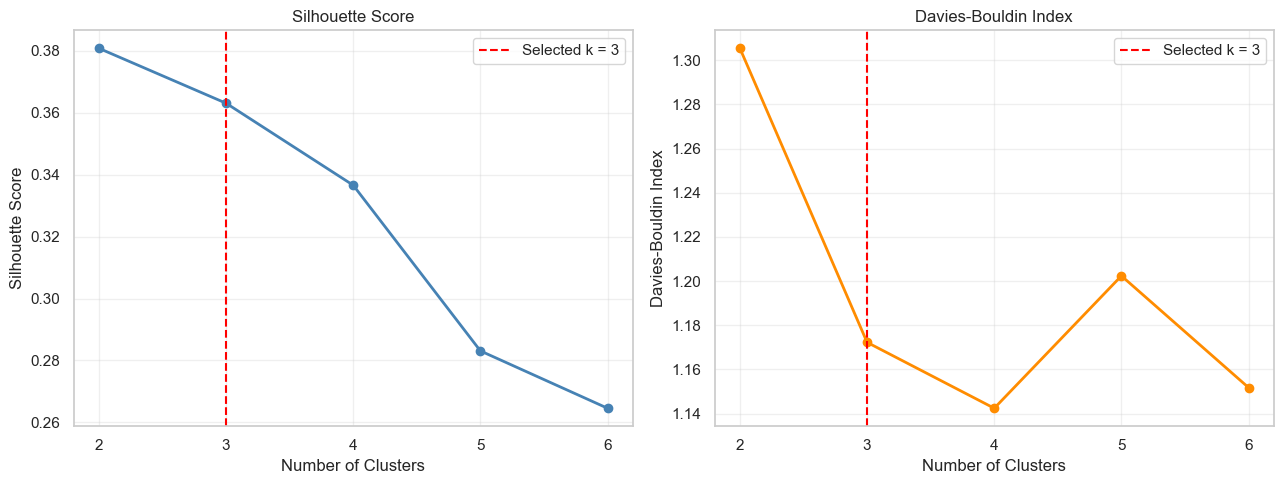

In [43]:
plt.close("all")

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(13, 5)
)

# Silhouette Score
axes[0].plot(
    cluster_evaluation["Number_of_Clusters"],
    cluster_evaluation["Silhouette_Score"],
    marker="o",
    linewidth=2,
    color="steelblue"
)

axes[0].set_title("Silhouette Score")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Silhouette Score")
axes[0].set_xticks(
    cluster_evaluation["Number_of_Clusters"]
)
axes[0].grid(alpha=0.3)

# Davies-Bouldin Index
axes[1].plot(
    cluster_evaluation["Number_of_Clusters"],
    cluster_evaluation["Davies_Bouldin_Index"],
    marker="o",
    linewidth=2,
    color="darkorange"
)

axes[1].set_title("Davies-Bouldin Index")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Davies-Bouldin Index")
axes[1].set_xticks(
    cluster_evaluation["Number_of_Clusters"]
)
axes[1].grid(alpha=0.3)

axes[0].axvline(
    x=3,
    color="red",
    linestyle="--",
    label="Selected k = 3"
)

axes[1].axvline(
    x=3,
    color="red",
    linestyle="--",
    label="Selected k = 3"
)

axes[0].legend()
axes[1].legend()
fig.tight_layout()
plt.show()

In [35]:
kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_final.fit_predict(pca_data)

clustering_data["KMeans_Cluster"] = kmeans_labels

print("Number of observations in each cluster:")
print(
    clustering_data["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)

Number of observations in each cluster:
KMeans_Cluster
0    1680
1     430
2     383
Name: count, dtype: int64


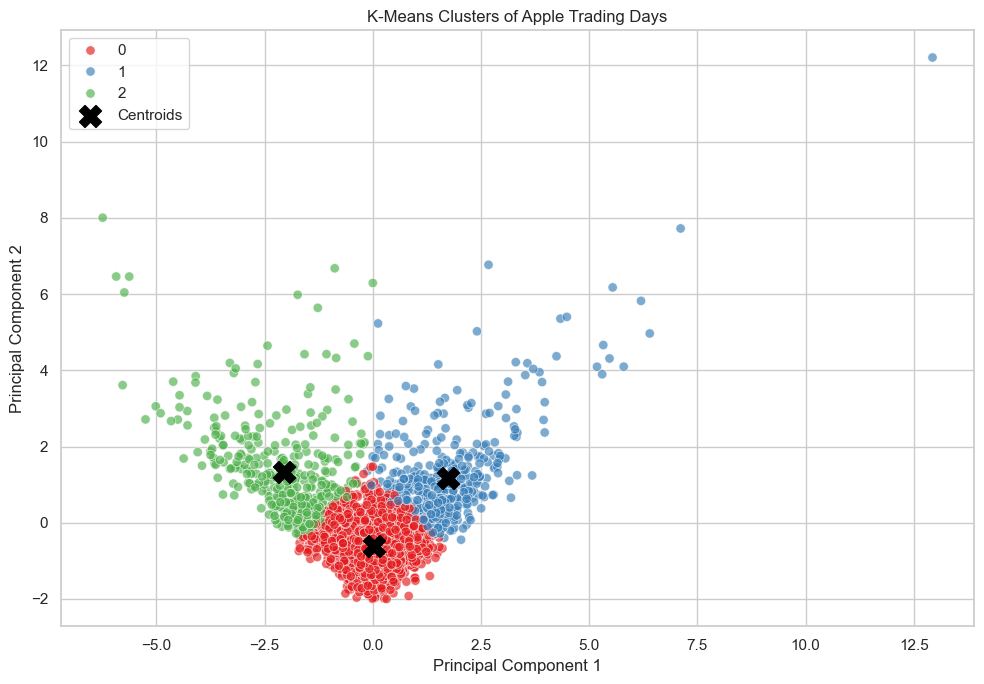

In [36]:
pca_plot = pca_data.copy()
pca_plot["Cluster"] = kmeans_labels

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_plot,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    alpha=0.65,
    s=45
)

plt.scatter(
    kmeans_final.cluster_centers_[:, 0],
    kmeans_final.cluster_centers_[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroids"
)

plt.title("K-Means Clusters of Apple Trading Days")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.show()

In [37]:
cluster_profile = (
    clustering_data
    .groupby("KMeans_Cluster")[feature_columns]
    .mean()
    .round(3)
)

cluster_profile

,Daily_Return,Intraday_Range,Open_Close_Change,Volume_Change,Rolling_Volatility
KMeans_Cluster,,,,,
0,0.113,1.499,0.085,-4.726,1.414
1,2.428,3.047,1.939,19.683,2.181
2,-2.429,3.418,-1.842,31.413,2.149


K-Means identified three significant market regimes. Cluster 0 represented relatively stable trading days with low returns and volatility. Cluster 1 contained highly active days with strong positive returns, while Cluster 2 represented highly active days with strong negative returns. The negative return cluster also exhibited the largest average intraday volume variation and amplitude

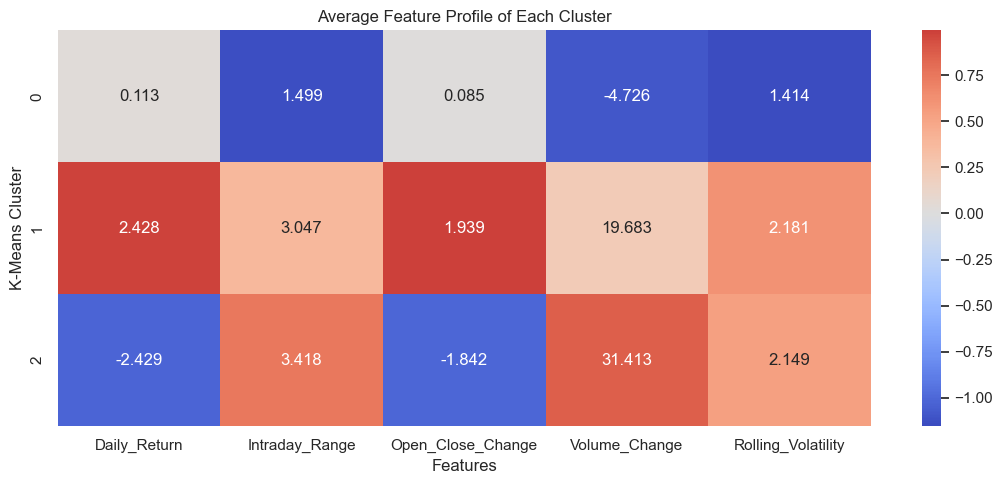

In [38]:
profile_scaled = (
    cluster_profile - cluster_profile.mean()
) / cluster_profile.std()

plt.figure(figsize=(11, 5))

sns.heatmap(
    profile_scaled,
    annot=cluster_profile,
    fmt=".3f",
    cmap="coolwarm",
    center=0
)

plt.title("Average Feature Profile of Each Cluster")
plt.xlabel("Features")
plt.ylabel("K-Means Cluster")
plt.tight_layout()
plt.show()

K-Means identified three distinct market regimes. Cluster 0 represents relatively stable trading days, Cluster 1 represents days with strong positive returns, and Cluster 2 represents days with strong negative returns and higher daily movement

In [39]:
cluster_names = {
    0: "Stable Market",
    1: "Positive High Activity",
    2: "Negative High Activity"
}

clustering_data["Market_Regime"] = (
    clustering_data["KMeans_Cluster"]
    .map(cluster_names)
)

print(clustering_data["Market_Regime"].value_counts())

Market_Regime
Stable Market             1680
Positive High Activity     430
Negative High Activity     383
Name: count, dtype: int64


In [40]:
regime_summary = (
    clustering_data["Market_Regime"]
    .value_counts()
    .to_frame(name="Number_of_Days")
)

regime_summary["Percentage"] = (
    regime_summary["Number_of_Days"]
    / len(clustering_data)
    * 100
).round(2)

regime_summary

,Number_of_Days,Percentage
Market_Regime,,
Stable Market,1680,67.39
Positive High Activity,430,17.25
Negative High Activity,383,15.36


Based on the data, it is possible to classify these as days of stable market conditions, which account for 67.39% of the dataset. Days of high positive activity represented 17.25%, while days of high negative activity accounted for 15.36%. This indicates that pronounced market movements—whether positive or negative—occurred less frequently than stable trading conditions.

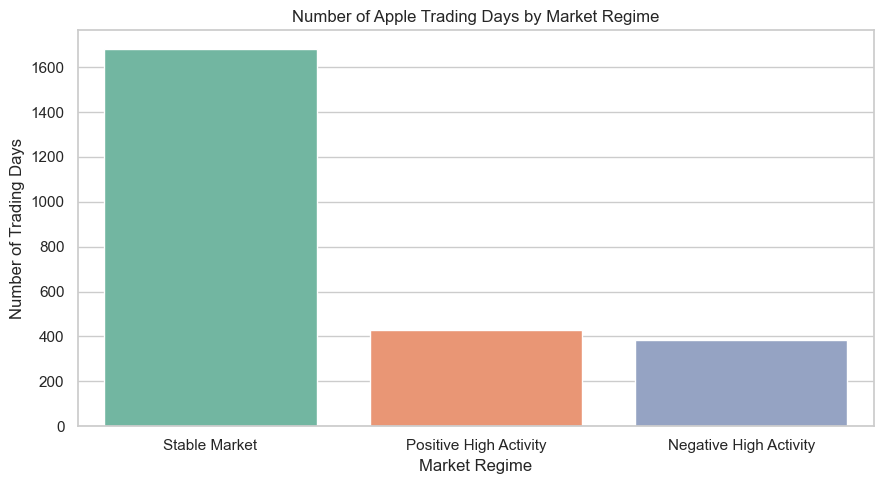

In [41]:
regime_counts = (
    clustering_data["Market_Regime"]
    .value_counts()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=regime_counts.index,
    y=regime_counts.values,
    hue=regime_counts.index,
    palette="Set2",
    legend=False
)

plt.title("Number of Apple Trading Days by Market Regime")
plt.xlabel("Market Regime")
plt.ylabel("Number of Trading Days")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

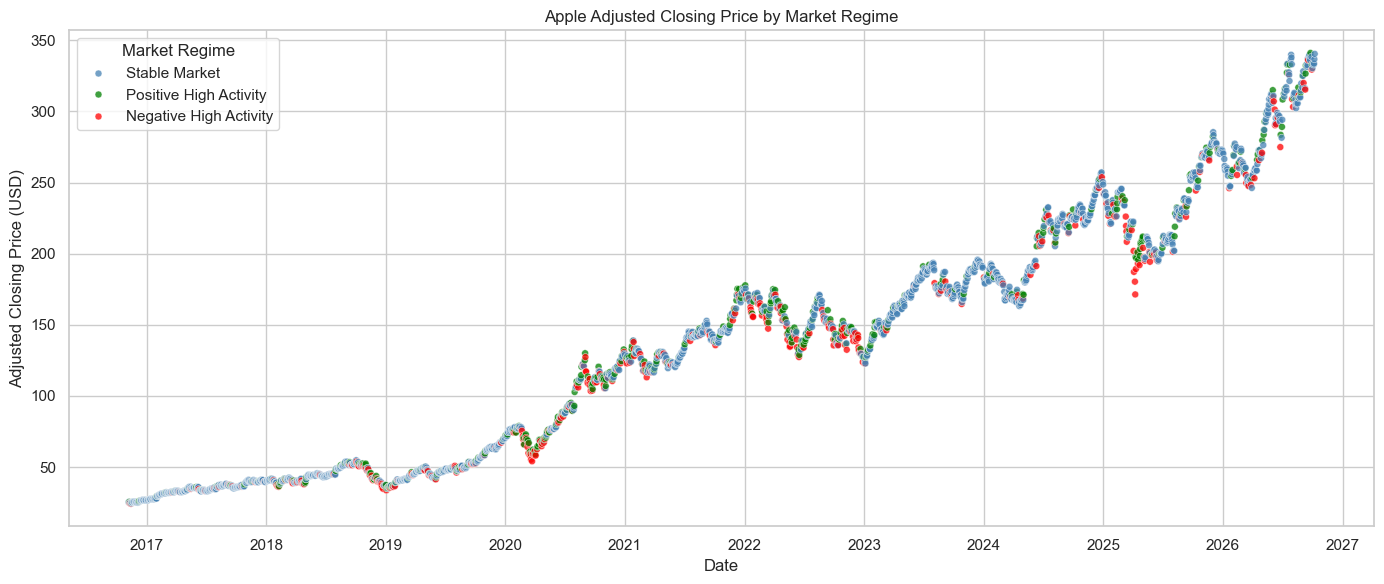

In [42]:
plt.figure(figsize=(14, 6))

sns.scatterplot(
    data=clustering_data,
    x="Date",
    y="Adj Close",
    hue="Market_Regime",
    palette={
        "Stable Market": "steelblue",
        "Positive High Activity": "green",
        "Negative High Activity": "red"
    },
    s=25,
    alpha=0.75
)

plt.title("Apple Adjusted Closing Price by Market Regime")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (USD)")
plt.legend(title="Market Regime")
plt.tight_layout()
plt.show()

The graph shows that Stable Market days were the most common throughout the period. Positive High Activity and Negative High Activity days occurred less often and appeared mainly during larger daily price movements. The three regimes were found at different stock price levels.